# 5_Appendix_Tables
Reproduces every appendix table and figure that is **not** already produced by notebooks 1 to 4,
plus the revised Table 1, and checks the key numbers used in the thesis.

**How to run:** put this notebook in the same folder as your CSV files, then click
**Kernel > Restart Kernel and Run All Cells** (in classic Jupyter: **Kernel > Restart & Run All**).
It takes about one minute.

**Output:** a folder called `appendix_output` next to this notebook, with one CSV per table and one PNG per figure.
The last cell prints a check of all key numbers. Every line should say `OK`.

**Never re-run the Google Trends notebooks.** A new download gives slightly different numbers.

In [1]:
# Cell 1: libraries and settings
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.vector_ar.var_model import VAR
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.stattools import durbin_watson
import warnings
warnings.filterwarnings("ignore")          # hides harmless KPSS and statsmodels notes

OUT = "appendix_output"                    # all tables and figures are saved here
os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Libraries loaded. Output folder:", os.path.abspath(OUT))

Libraries loaded. Output folder: /Users/marcov/Thesis/Clean/Clean for VAR/appendix_output


## 1. Load the data
This cell checks that all input files are in the folder before loading them.

In [2]:
# Cell 2: check that every input file is present
FILES = ["spy_clean.csv", "rsp_clean.csv", "voo_clean.csv", "vix_clean.csv", "dgs10_clean.csv",
         "AIStocks_ASVI8_Monthly.csv", "AIStocks_ASVI4_Monthly.csv", "mag7_clean.csv",
         "Mag7 Monthly Returns.csv"]
missing = [f for f in FILES if not os.path.exists(f)]
if missing:
    raise FileNotFoundError("These files are missing from the notebook folder: " + ", ".join(missing))
print("All 9 input files found.")

All 9 input files found.


In [3]:
# Cell 3: load and merge the clean CSVs (same merge as notebook 1)
def load(name):
    return pd.read_csv(name, parse_dates=["date"])

df = (load("spy_clean.csv")
      .merge(load("rsp_clean.csv"), on="date")
      .merge(load("voo_clean.csv"), on="date")
      .merge(load("vix_clean.csv"), on="date")
      .merge(load("dgs10_clean.csv"), on="date")
      .merge(load("AIStocks_ASVI8_Monthly.csv"), on="date")
      .merge(load("AIStocks_ASVI4_Monthly.csv"), on="date")
      .merge(load("mag7_clean.csv"), on="date"))

# Mag7B (without TSLA) and Mag7C (NVDA, MSFT, GOOGL, META), built from the Compustat file
m = pd.read_csv("Mag7 Monthly Returns.csv")
m.columns = ["tic", "date", "gvkey", "conm", "trt1m"]
m["date"] = pd.to_datetime(m["date"], format="%d.%m.%Y")
m["logret"] = np.log(1 + m["trt1m"] / 100)          # trt1m is a monthly total return in percent
wide = m.pivot(index="date", columns="tic", values="logret")
baskets = pd.DataFrame({
    "date": wide.index,
    "mag7_check": wide.mean(axis=1).values,
    "mag7b_ret": wide.drop(columns=["TSLA"]).mean(axis=1).values,
    "mag7c_ret": wide[["NVDA", "MSFT", "GOOGL", "META"]].mean(axis=1).values,
})
df = df.merge(baskets, on="date").sort_values("date").reset_index(drop=True)

# Safety checks
assert len(df) == 121, f"Expected 121 months, got {len(df)}"
assert (df["mag7_ret"] - df["mag7_check"]).abs().max() < 1e-6, "Mag7 basket does not match mag7_clean.csv"
df = df.drop(columns="mag7_check")

# 2021-2025 subsample: December 2020 is kept as the initial lag, so estimation runs Jan 2021 to Dec 2025
sub = df[df["date"] >= "2020-12-31"].copy()
assert len(sub) == 61

print(f"Full sample: {len(df)} rows ({df.date.min().date()} to {df.date.max().date()}), 120 used in estimation")
print(f"Subsample:   {len(sub)} rows ({sub.date.min().date()} to {sub.date.max().date()}), 60 used in estimation")

Full sample: 121 rows (2015-12-31 to 2025-12-31), 120 used in estimation
Subsample:   61 rows (2020-12-31 to 2025-12-31), 60 used in estimation


In [4]:
# Cell 4: names and helper functions used below
LABEL = {"dlog_vix": "dlogVIX", "dy10": "dy10", "ASVI8": "ASVI8", "ASVI4": "ASVI4",
         "flow_spy": "Flow SPY", "flow_rsp": "Flow RSP", "flow_voo": "Flow VOO",
         "mag7_ret": "Mag7 returns", "mag7b_ret": "Mag7B returns", "mag7c_ret": "Mag7C returns"}
BASE = ["dlog_vix", "dy10", "ASVI8", "flow_spy", "mag7_ret"]   # Cholesky order of the primary VAR
SAMPLES = [("Full sample", df), ("2021-2025", sub)]

def fit(data, cols):
    # VAR(1), the specification used throughout the thesis
    return VAR(data[cols].reset_index(drop=True)).fit(1)

def max_eigenvalue(res):
    # Largest eigenvalue modulus of the companion matrix (stable if below 1).
    # statsmodels' results.roots are the roots of the characteristic polynomial, i.e. 1 / eigenvalues.
    return 1 / np.abs(res.roots).min()

def save(table, name):
    path = os.path.join(OUT, name)
    table.to_csv(path, index=False)
    print("Saved", path)

## 2. Revised Table 1 (descriptive statistics)
`AR(1)` is the sample first-order autocorrelation. `Own lag` is the variable's own-lag coefficient in its VAR(1).

In [5]:
# Cell 5: revised Table 1
own = {}
r_spy = fit(df, BASE)
for c in BASE:
    own[c] = r_spy.params[c]["L1." + c]
for fl in ["flow_rsp", "flow_voo"]:
    own[fl] = fit(df, ["dlog_vix", "dy10", "ASVI8", fl, "mag7_ret"]).params[fl]["L1." + fl]
own["ASVI4"] = fit(df, ["dlog_vix", "dy10", "ASVI4", "flow_spy", "mag7_ret"]).params["ASVI4"]["L1.ASVI4"]

rows = []
for c in ["dlog_vix", "dy10", "ASVI8", "ASVI4", "flow_spy", "flow_rsp", "flow_voo", "mag7_ret"]:
    s = df[c]
    rows.append([LABEL[c], s.mean(), s.std(), s.min(), s.max(), s.autocorr(1), own[c], len(s)])
table1 = pd.DataFrame(rows, columns=["Variable", "Mean", "SD", "Min", "Max", "AR(1)", "Own lag", "N"]).round(3)
save(table1, "Table_1_revised.csv")
table1

Saved appendix_output/Table_1_revised.csv


,Variable,Mean,SD,Min,Max,AR(1),Own lag,N
0,dlogVIX,-0.001,0.232,-0.614,0.756,-0.293,-0.180,121
1,dy10,0.016,0.242,-0.520,0.680,0.092,0.100,121
2,ASVI8,0.230,0.552,-0.693,2.398,0.794,0.771,121
3,ASVI4,0.103,0.475,-0.693,1.992,0.637,0.627,121
4,Flow SPY,0.001,0.027,-0.067,0.094,-0.220,-0.236,121
5,Flow RSP,0.009,0.034,-0.111,0.147,0.388,0.316,121
6,Flow VOO,0.014,0.016,-0.036,0.064,0.028,0.007,121
7,Mag7 returns,0.023,0.074,-0.197,0.200,-0.014,-0.126,121


## 3. Appendix A: stationarity, baskets, raw search volume

In [6]:
# Cell 6: Table A.2, ADF (constant, lags by AIC) and KPSS (level stationarity, automatic lags)
rows = []
for c in ["dlog_vix", "dy10", "ASVI8", "ASVI4", "flow_spy", "flow_rsp", "flow_voo",
          "mag7_ret", "mag7b_ret", "mag7c_ret"]:
    a = adfuller(df[c], autolag="AIC")
    k = kpss(df[c], regression="c", nlags="auto")
    rows.append([LABEL[c], a[0], a[1], a[2], k[0], k[1], k[2]])
tA2 = pd.DataFrame(rows, columns=["Variable", "ADF stat", "ADF p", "ADF lags", "KPSS stat", "KPSS p (capped at 0.10)", "KPSS lags"])
tA2["ADF p"] = tA2["ADF p"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
save(tA2.round(3), "Table_A2_stationarity.csv")
tA2.round(3)

Saved appendix_output/Table_A2_stationarity.csv


,Variable,ADF stat,ADF p,ADF lags,KPSS stat,KPSS p (capped at 0.10),KPSS lags
0,dlogVIX,-14.697,<0.001,0,0.049,0.1,5
1,dy10,-9.892,<0.001,0,0.139,0.1,2
2,ASVI8,-5.023,<0.001,2,0.199,0.1,5
3,ASVI4,-7.322,<0.001,1,0.144,0.1,4
4,Flow SPY,-10.094,<0.001,1,0.133,0.1,11
5,Flow RSP,-7.206,<0.001,0,0.238,0.1,3
6,Flow VOO,-9.747,<0.001,1,0.179,0.1,6
7,Mag7 returns,-11.013,<0.001,0,0.055,0.1,0
8,Mag7B returns,-10.807,<0.001,0,0.051,0.1,2
9,Mag7C returns,-10.537,<0.001,0,0.056,0.1,3


In [7]:
# Cell 7: Table A.3, return baskets
rows = [[LABEL[c], df[c].mean(), df[c].std(), df[c].min(), df[c].max(), df[c].autocorr(1)]
        for c in ["mag7_ret", "mag7b_ret", "mag7c_ret"]]
tA3 = pd.DataFrame(rows, columns=["Basket", "Mean", "SD", "Min", "Max", "AR(1)"]).round(3)
save(tA3, "Table_A3_baskets.csv")
print(df[["mag7_ret", "mag7b_ret", "mag7c_ret"]].corr().round(3))
tA3

Saved appendix_output/Table_A3_baskets.csv
           mag7_ret  mag7b_ret  mag7c_ret
mag7_ret      1.000      0.959      0.914
mag7b_ret     0.959      1.000      0.974
mag7c_ret     0.914      0.974      1.000


,Basket,Mean,SD,Min,Max,AR(1)
0,Mag7 returns,0.023,0.074,-0.197,0.200,-0.014
1,Mag7B returns,0.022,0.068,-0.194,0.161,0.005
2,Mag7C returns,0.024,0.072,-0.198,0.164,0.030


Saved appendix_output/AIStocks_SVI_raw_reconstructed.csv
Months with SVI = 0: 17
Highest SVI before 2023: 5
Last five months: [100, 79, 74, 74, 69] (should be 100, 79, 74, 74, 69)


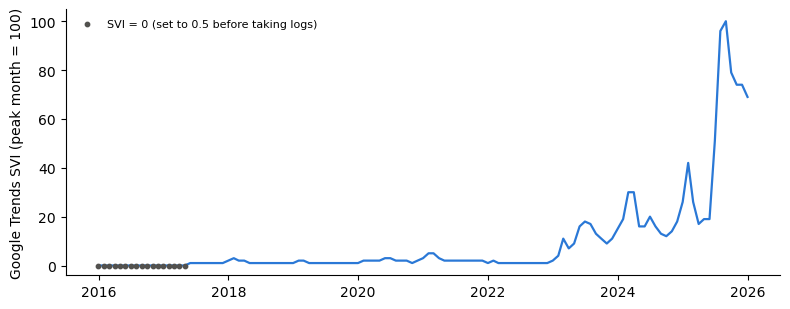

In [8]:
# Cell 8: Figure A.1, raw Google Trends SVI rebuilt exactly from the ASVI8 file (no new download)
# ASVI8_t = log(SVI_t) - log(median of SVI over t-8 ... t-1), with SVI = 0 replaced by 0.5.
# Starting from the eight zero months before December 2015, every raw value can be recovered.
def rebuild_svi(asvi, window):
    svi = [0.5] * window
    for x in asvi:
        v = np.median(svi[-window:]) * np.exp(x)
        svi.append(0.5 if abs(v - 0.5) < 1e-6 else round(v))
    return [0 if v == 0.5 else int(v) for v in svi[window:]]

df["SVI"] = rebuild_svi(df["ASVI8"], 8)
assert df["SVI"].tolist() == rebuild_svi(df["ASVI4"], 4), "ASVI8 and ASVI4 files imply different raw data"
save(df[["date", "SVI"]], "AIStocks_SVI_raw_reconstructed.csv")

print("Months with SVI = 0:", (df.SVI == 0).sum())
print("Highest SVI before 2023:", df.loc[df.date < "2023-01-01", "SVI"].max())
print("Last five months:", df.SVI.tail().tolist(), "(should be 100, 79, 74, 74, 69)")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(df.date, df.SVI, color="#2a78d6", lw=1.6)
zero = df[df.SVI == 0]
ax.scatter(zero.date, zero.SVI, s=10, color="#52514e", zorder=3, label="SVI = 0 (set to 0.5 before taking logs)")
ax.set_ylabel("Google Trends SVI (peak month = 100)")
ax.set_ylim(-4, 105)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(OUT, "Figure_A1_raw_SVI.png"), dpi=300)
plt.show()

## 4. Appendix B: lag selection and diagnostics

In [9]:
# Cell 9: Table B.1, lag-order selection for VAR-SPY (lags 0 to 4)
rows = []
for name, d in SAMPLES:
    so = VAR(d[BASE].reset_index(drop=True)).select_order(maxlags=4)
    for p in range(5):
        rows.append([name, p, so.ics["aic"][p], so.ics["bic"][p], so.ics["fpe"][p], so.ics["hqic"][p]])
    print(name, "selected lags:", {k: int(v) for k, v in so.selected_orders.items()})
tB1 = pd.DataFrame(rows, columns=["Sample", "Lag", "AIC", "BIC", "FPE", "HQIC"])
save(tB1, "Table_B1_lag_selection.csv")
tB1.round(3)

Full sample selected lags: {'aic': 2, 'bic': 1, 'hqic': 1, 'fpe': 2}
2021-2025 selected lags: {'aic': 1, 'bic': 1, 'hqic': 1, 'fpe': 1}
Saved appendix_output/Table_B1_lag_selection.csv


,Sample,Lag,AIC,BIC,FPE,HQIC
0,Full sample,0,-19.774,-19.656,0.0,-19.726
1,Full sample,1,-20.655,-19.946,0.0,-20.367
2,Full sample,2,-20.671,-19.373,0.0,-20.144
3,Full sample,3,-20.493,-18.604,0.0,-19.726
4,Full sample,4,-20.364,-17.885,0.0,-19.357
5,2021-2025,0,-19.551,-19.372,0.0,-19.481
6,2021-2025,1,-20.614,-19.538,0.0,-20.196
7,2021-2025,2,-20.593,-18.622,0.0,-19.827
8,2021-2025,3,-20.430,-17.562,0.0,-19.315
9,2021-2025,4,-20.561,-16.797,0.0,-19.098


In [10]:
# Cell 10: all 22 VAR specifications (used for Tables B.2 and C.3)
specs = []
for name, d in SAMPLES:
    for ret, basket in [("mag7_ret", "Mag7"), ("mag7b_ret", "Mag7B"), ("mag7c_ret", "Mag7C")]:
        for fl in ["flow_spy", "flow_rsp", "flow_voo"]:
            specs.append((basket, fl[5:].upper(), name, ["dlog_vix", "dy10", "ASVI8", fl, ret], ret, d))
    specs.append(("Mag7", "none (3-variable)", name, ["dlog_vix", "ASVI8", "mag7_ret"], "mag7_ret", d))
    specs.append(("Mag7 (ASVI4)", "SPY", name, ["dlog_vix", "dy10", "ASVI4", "flow_spy", "mag7_ret"], "mag7_ret", d))

b2, c3 = [], []
for basket, fund, name, cols, ret, d in specs:
    r = fit(d, cols)
    att = "ASVI4" if "ASVI4" in cols else "ASVI8"
    flow = [c for c in cols if c.startswith("flow")]
    bic = VAR(d[cols].reset_index(drop=True)).select_order(maxlags=4).selected_orders["bic"]
    w, n = r.test_whiteness(nlags=10), r.test_normality()
    b2.append([basket, fund, name, bic, max_eigenvalue(r), w.test_statistic, w.pvalue, n.test_statistic, n.pvalue])
    g = r.test_causality(ret, [att], kind="f")
    fb = r.test_causality(att, [ret], kind="f")
    a2f = r.test_causality(flow[0], [att], kind="f").pvalue if flow else np.nan
    f2r = r.test_causality(ret, [flow[0]], kind="f").pvalue if flow else np.nan
    fe = r.fevd(12).decomp[cols.index(ret)][11] * 100
    c3.append([basket, fund, name, r.params[ret]["L1." + att], r.stderr[ret]["L1." + att], g.test_statistic, g.pvalue,
               a2f, f2r, fb.pvalue, fe[cols.index(att)], fe[cols.index(flow[0])] if flow else np.nan, int(r.nobs)])

tB2 = pd.DataFrame(b2, columns=["Basket", "Flow", "Sample", "BIC lag", "Largest eigenvalue modulus", "Portmanteau stat",
                                "Portmanteau p", "Normality stat", "Normality p"])
tC3 = pd.DataFrame(c3, columns=["Basket", "Flow", "Sample", "beta L1.attention", "SE", "Granger F (attention -> returns)", "p",
                                "p (attention -> flow)", "p (flow -> returns)", "p (returns -> attention)",
                                "FEVD attention h=12 (%)", "FEVD flow h=12 (%)", "N"])
save(tB2, "Table_B2_diagnostics_all_specs.csv")
save(tC3, "Table_C3_granger_fevd_all_specs.csv")
tB2.round(3)

Saved appendix_output/Table_B2_diagnostics_all_specs.csv
Saved appendix_output/Table_C3_granger_fevd_all_specs.csv


,Basket,Flow,Sample,BIC lag,Largest eigenvalue modulus,Portmanteau stat,Portmanteau p,Normality stat,Normality p
0,Mag7,SPY,Full sample,1,0.793,234.858,0.312,57.645,0.000
1,Mag7,RSP,Full sample,1,0.789,240.984,0.221,110.243,0.000
2,Mag7,VOO,Full sample,1,0.791,240.127,0.233,29.022,0.001
3,Mag7B,SPY,Full sample,1,0.794,229.207,0.410,59.459,0.000
4,Mag7B,RSP,Full sample,1,0.791,230.986,0.378,112.551,0.000
5,Mag7B,VOO,Full sample,1,0.792,238.233,0.260,29.183,0.001
6,Mag7C,SPY,Full sample,1,0.793,228.211,0.428,59.442,0.000
7,Mag7C,RSP,Full sample,1,0.790,236.881,0.280,112.285,0.000
8,Mag7C,VOO,Full sample,1,0.791,240.985,0.221,28.546,0.001
9,Mag7,none (3-variable),Full sample,1,0.793,108.470,0.023,27.810,0.000


In [11]:
# Cell 11: show Table C.3
tC3.round(4)

,Basket,Flow,Sample,beta L1.attention,SE,Granger F (attention -> returns),p,p (attention -> flow),p (flow -> returns),p (returns -> attention),FEVD attention h=12 (%),FEVD flow h=12 (%),N
0,Mag7,SPY,Full sample,0.0274,0.0128,4.6249,0.0319,0.2097,0.9763,0.1921,4.8304,0.4865,120
1,Mag7,RSP,Full sample,0.0269,0.0127,4.4911,0.0345,0.9126,0.4825,0.1614,4.8277,0.4662,120
2,Mag7,VOO,Full sample,0.0274,0.0127,4.6594,0.0313,0.9249,0.7653,0.1631,4.7714,1.2010,120
3,Mag7B,SPY,Full sample,0.0306,0.0118,6.6821,0.0100,0.2188,0.9845,0.2023,6.1078,0.2972,120
4,Mag7B,RSP,Full sample,0.0304,0.0118,6.6558,0.0101,0.9592,0.7197,0.1848,6.1895,0.4742,120
5,Mag7B,VOO,Full sample,0.0305,0.0118,6.7318,0.0097,0.8844,0.6106,0.1542,5.8982,2.2975,120
6,Mag7C,SPY,Full sample,0.0349,0.0127,7.5488,0.0062,0.2002,0.9421,0.0990,7.9520,0.3339,120
7,Mag7C,RSP,Full sample,0.0348,0.0127,7.5582,0.0062,0.9357,0.9839,0.0892,8.1660,0.5218,120
8,Mag7C,VOO,Full sample,0.0347,0.0126,7.5580,0.0062,0.7736,0.5578,0.0718,7.7090,2.2399,120
9,Mag7,none (3-variable),Full sample,0.0275,0.0126,4.7778,0.0295,NaN,NaN,0.1435,5.2184,NaN,120


In [12]:
# Cell 12: Table B.3, residual correlation matrices of VAR-SPY
for name, d in SAMPLES:
    r = fit(d, BASE)
    corr = pd.DataFrame(np.corrcoef(np.asarray(r.resid).T), index=[LABEL[c] for c in BASE], columns=[LABEL[c] for c in BASE])
    save(corr.round(3).reset_index().rename(columns={"index": ""}), f"Table_B3_residual_corr_{name[:4]}.csv")
    print(name); print(corr.round(3)); print()

Saved appendix_output/Table_B3_residual_corr_Full.csv
Full sample
              dlogVIX   dy10  ASVI8  Flow SPY  Mag7 returns
dlogVIX         1.000  0.034 -0.049    -0.264        -0.535
dy10            0.034  1.000 -0.045     0.022        -0.172
ASVI8          -0.049 -0.045  1.000     0.038         0.169
Flow SPY       -0.264  0.022  0.038     1.000         0.207
Mag7 returns   -0.535 -0.172  0.169     0.207         1.000

Saved appendix_output/Table_B3_residual_corr_2021.csv
2021-2025
              dlogVIX   dy10  ASVI8  Flow SPY  Mag7 returns
dlogVIX         1.000  0.341 -0.070    -0.309        -0.511
dy10            0.341  1.000  0.002    -0.245        -0.416
ASVI8          -0.070  0.002  1.000    -0.156         0.196
Flow SPY       -0.309 -0.245 -0.156     1.000         0.158
Mag7 returns   -0.511 -0.416  0.196     0.158         1.000



## 5. Appendix C: full VAR equations, FEVD for RSP and VOO, OLS tables, ordering check

In [13]:
# Cell 13: Tables C.1 and C.2, all five equations of VAR-SPY
for name, d in SAMPLES:
    r = fit(d, BASE)
    rows = []
    for v in ["const"] + ["L1." + c for c in BASE]:
        row = [v]
        for e in BASE:
            row += [r.params[e][v], r.stderr[e][v], r.pvalues[e][v]]
        rows.append(row)
    cols = ["Regressor"] + [f"{LABEL[e]} {k}" for e in BASE for k in ("coef", "SE", "p")]
    t = pd.DataFrame(rows, columns=cols)
    save(t, "Table_C1_VAR_SPY_full.csv" if name == "Full sample" else "Table_C2_VAR_SPY_2021.csv")
    print(f"{name}: N = {int(r.nobs)}, log-likelihood = {r.llf:.1f}, AIC = {r.aic:.2f}, BIC = {r.bic:.2f}")

Saved appendix_output/Table_C1_VAR_SPY_full.csv
Full sample: N = 120, log-likelihood = 421.1, AIC = -20.71, BIC = -20.01
Saved appendix_output/Table_C2_VAR_SPY_2021.csv
2021-2025: N = 60, log-likelihood = 220.0, AIC = -20.52, BIC = -19.47


In [14]:
# Cell 14: Table C.4, FEVD of Mag7 returns in VAR-RSP and VAR-VOO (percent, h = 1, 6, 12)
rows = []
for fl in ["flow_rsp", "flow_voo"]:
    cols = ["dlog_vix", "dy10", "ASVI8", fl, "mag7_ret"]
    for name, d in SAMPLES:
        fe = fit(d, cols).fevd(12).decomp[4] * 100
        for i, c in enumerate(cols):
            rows.append([fl[5:].upper(), name, LABEL[c], fe[0][i], fe[5][i], fe[11][i]])
tC4 = pd.DataFrame(rows, columns=["Fund", "Sample", "Shock", "h=1", "h=6", "h=12"])
save(tC4.round(1), "Table_C4_FEVD_RSP_VOO.csv")
tC4.round(1)

Saved appendix_output/Table_C4_FEVD_RSP_VOO.csv


,Fund,Sample,Shock,h=1,h=6,h=12
0,RSP,Full sample,dlogVIX,28.0,27.1,27.0
1,RSP,Full sample,dy10,2.2,2.3,2.3
2,RSP,Full sample,ASVI8,1.9,4.6,4.8
3,RSP,Full sample,Flow RSP,0.0,0.5,0.5
4,RSP,Full sample,Mag7 returns,67.8,65.5,65.3
5,RSP,2021-2025,dlogVIX,24.9,23.3,23.1
6,RSP,2021-2025,dy10,7.5,6.9,6.8
7,RSP,2021-2025,ASVI8,3.3,10.1,11.1
8,RSP,2021-2025,Flow RSP,0.0,0.4,0.5
9,RSP,2021-2025,Mag7 returns,64.4,59.3,58.5


In [15]:
# Cell 15: Tables C.5 and C.6, baseline OLS by sample window (HC3 standard errors,
# contemporaneous dlogVIX and dy10 as controls, as in the Baseline OLS notebook)
d0 = df.copy()
for c in ["ASVI8", "flow_spy", "flow_rsp", "flow_voo", "mag7_ret"]:
    d0[c + "_lag"] = d0[c].shift(1)
d0 = d0.dropna(subset=["ASVI8_lag"])

def ols(data, y, x):
    m = sm.OLS(data[y], sm.add_constant(data[[x, "dlog_vix", "dy10"]])).fit(cov_type="HC3")
    return [m.params[x], m.bse[x], m.tvalues[x], m.pvalues[x], m.rsquared, durbin_watson(m.resid), int(m.nobs)]

windows = [("2016-2025", None), ("2020-2025", "2020-01-31"), ("2021-2025", "2021-01-31"),
           ("2022-2025", "2022-01-31"), ("2023-2025", "2023-01-31")]
rows5, rows6 = [], []
for w, start in windows:
    s = d0 if start is None else d0[d0.date >= start]
    for fl in ["flow_spy", "flow_rsp", "flow_voo"]:
        rows5.append([w, "H1: ASVI8(t-1) -> " + LABEL[fl]] + ols(s, fl, "ASVI8_lag"))
        rows5.append([w, "H1b: " + LABEL[fl] + "(t-1) -> Mag7"] + ols(s, "mag7_ret", fl + "_lag"))
    rows6.append([w, "H2: ASVI8(t-1) -> Mag7"] + ols(s, "mag7_ret", "ASVI8_lag"))
    rows6.append([w, "Feedback: Mag7(t-1) -> ASVI8"] + ols(s, "ASVI8", "mag7_ret_lag"))
cols = ["Window", "Regression", "coef", "SE (HC3)", "t", "p", "R2", "Durbin-Watson", "N"]
tC5, tC6 = pd.DataFrame(rows5, columns=cols), pd.DataFrame(rows6, columns=cols)
save(tC5, "Table_C5_OLS_flows.csv")
save(tC6, "Table_C6_OLS_returns_feedback.csv")
tC6.round(4)

Saved appendix_output/Table_C5_OLS_flows.csv
Saved appendix_output/Table_C6_OLS_returns_feedback.csv


,Window,Regression,coef,SE (HC3),t,p,R2,Durbin-Watson,N
0,2016-2025,H2: ASVI8(t-1) -> Mag7,0.0231,0.0106,2.1771,0.0295,0.2874,2.0396,120
1,2016-2025,Feedback: Mag7(t-1) -> ASVI8,2.3110,0.8857,2.6091,0.0091,0.0925,0.5061,120
2,2020-2025,H2: ASVI8(t-1) -> Mag7,0.0242,0.0124,1.9499,0.0512,0.3297,2.0892,72
3,2020-2025,Feedback: Mag7(t-1) -> ASVI8,2.8419,1.1391,2.4949,0.0126,0.1420,0.4992,72
4,2021-2025,H2: ASVI8(t-1) -> Mag7,0.0267,0.0131,2.0446,0.0409,0.3756,2.0378,60
5,2021-2025,Feedback: Mag7(t-1) -> ASVI8,3.7016,1.4713,2.5159,0.0119,0.1742,0.5744,60
6,2022-2025,H2: ASVI8(t-1) -> Mag7,0.0330,0.0139,2.3696,0.0178,0.4588,2.0763,48
7,2022-2025,Feedback: Mag7(t-1) -> ASVI8,4.5415,1.4466,3.1394,0.0017,0.2955,0.7137,48
8,2023-2025,H2: ASVI8(t-1) -> Mag7,0.0140,0.0158,0.8819,0.3779,0.2655,1.7898,36
9,2023-2025,Feedback: Mag7(t-1) -> ASVI8,4.4123,2.6604,1.6585,0.0972,0.2062,0.4145,36


In [16]:
# Cell 16: Table C.7, sensitivity to the Cholesky ordering (ASVI8 moved to the last position)
rows = []
for name, d in SAMPLES:
    for label, cols in [("Baseline: dlogVIX, dy10, ASVI8, Flow SPY, Mag7", BASE),
                        ("ASVI8 last: dlogVIX, dy10, Flow SPY, Mag7, ASVI8", ["dlog_vix", "dy10", "flow_spy", "mag7_ret", "ASVI8"])]:
        r = fit(d, cols)
        irf = r.irf(12)
        i_r, i_a = cols.index("mag7_ret"), cols.index("ASVI8")
        o, se = irf.orth_irfs[:, i_r, i_a], irf.stderr(orth=True)[:, i_r, i_a]
        fe = r.fevd(12).decomp[i_r] * 100
        rows.append([name, label, fe[0][i_a], fe[5][i_a], fe[11][i_a], o[0] * 100, o[1] * 100,
                     (o[1] - 1.959964 * se[1]) * 100, (o[1] + 1.959964 * se[1]) * 100])
tC7 = pd.DataFrame(rows, columns=["Sample", "Ordering", "FEVD h=1 (%)", "FEVD h=6 (%)", "FEVD h=12 (%)",
                                  "IRF t=0 (%)", "IRF t=1 (%)", "t=1 lower 95%", "t=1 upper 95%"])
save(tC7, "Table_C7_ordering.csv")
tC7.round(3)

Saved appendix_output/Table_C7_ordering.csv


,Sample,Ordering,FEVD h=1 (%),FEVD h=6 (%),FEVD h=12 (%),IRF t=0 (%),IRF t=1 (%),t=1 lower 95%,t=1 upper 95%
0,Full sample,"Baseline: dlogVIX, dy10, ASVI8, Flow SPY, Mag7",1.867,4.558,4.830,1.008,0.802,-0.033,1.637
1,Full sample,"ASVI8 last: dlogVIX, dy10, Flow SPY, Mag7, ASVI8",0.000,2.997,3.256,0.000,0.915,0.073,1.757
2,2021-2025,"Baseline: dlogVIX, dy10, ASVI8, Flow SPY, Mag7",2.824,9.818,10.937,1.305,1.374,0.198,2.551
3,2021-2025,"ASVI8 last: dlogVIX, dy10, Flow SPY, Mag7, ASVI8",0.000,6.879,7.901,0.000,1.395,0.203,2.587


## 6. Appendix D: impulse response grids (Figures D.1 and D.2)
Table D.1 and Figure D.3 come from the corrected bootstrap cell in notebook 1.

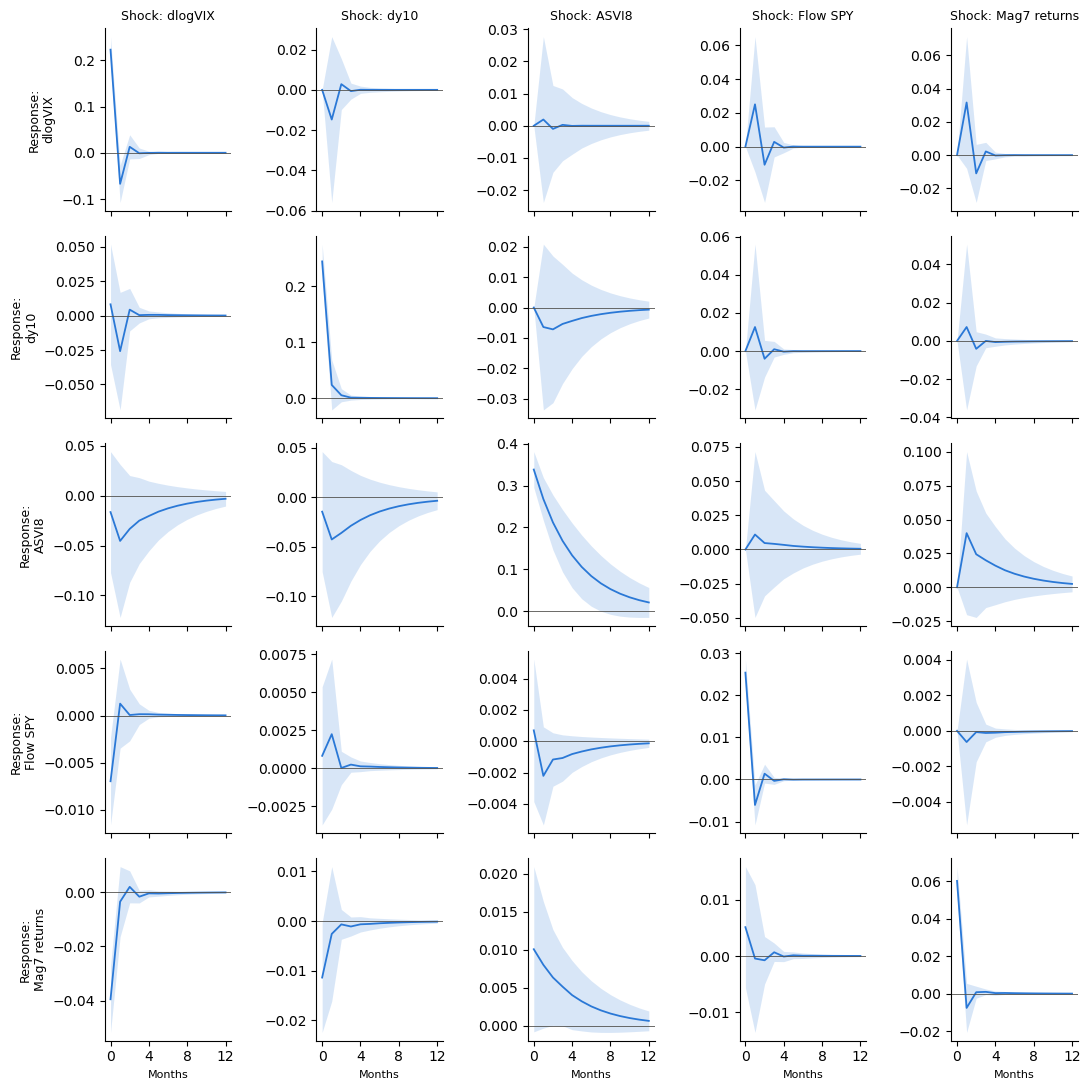

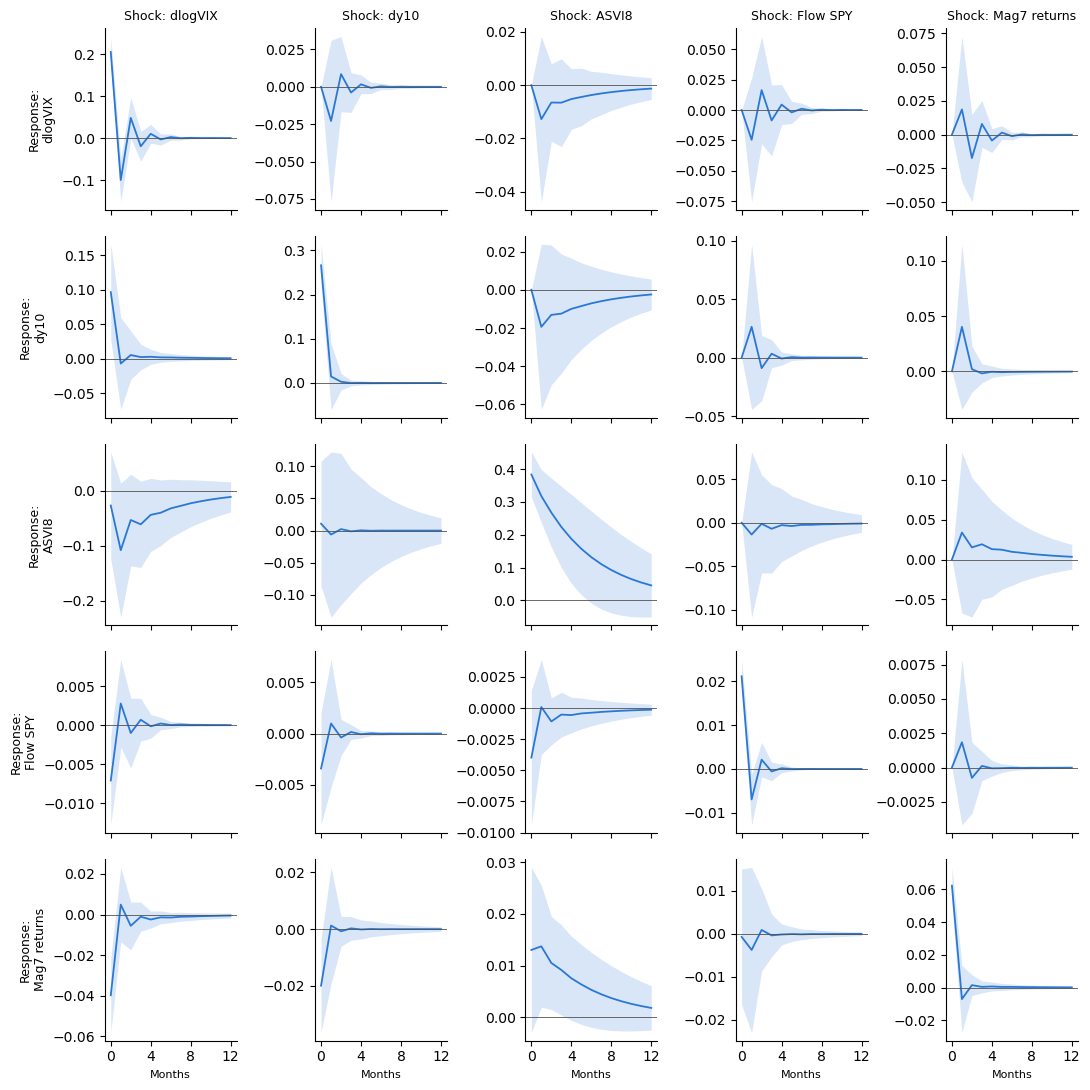

In [17]:
# Cell 17: Figures D.1 and D.2, all 25 orthogonalized impulse responses with 95% asymptotic bands
names = ["dlogVIX", "dy10", "ASVI8", "Flow SPY", "Mag7 returns"]
for name, d in SAMPLES:
    irf = fit(d, BASE).irf(12)
    o, se = irf.orth_irfs, irf.stderr(orth=True)
    h = np.arange(o.shape[0])
    fig, axes = plt.subplots(5, 5, figsize=(11, 11), sharex=True)
    for i in range(5):          # row = response
        for j in range(5):      # column = shock
            ax = axes[i, j]
            ax.fill_between(h, o[:, i, j] - 1.959964 * se[:, i, j], o[:, i, j] + 1.959964 * se[:, i, j],
                            color="#2a78d6", alpha=0.18, lw=0)
            ax.plot(h, o[:, i, j], color="#2a78d6", lw=1.3)
            ax.axhline(0, color="#52514e", lw=0.6)
            ax.spines[["top", "right"]].set_visible(False)
            if i == 0: ax.set_title("Shock: " + names[j], fontsize=9)
            if j == 0: ax.set_ylabel("Response:\n" + names[i], fontsize=9)
            if i == 4: ax.set_xticks([0, 4, 8, 12]); ax.set_xlabel("Months", fontsize=8)
    plt.tight_layout()
    fname = "Figure_D1_IRF_full.png" if name == "Full sample" else "Figure_D2_IRF_2021.png"
    plt.savefig(os.path.join(OUT, fname), dpi=300)
    plt.show()

## 7. Key number check
Compares the numbers this notebook computes with the values written in the thesis (Key Numbers table).
Every line should say `OK`. A `CHECK` means something in your data or code differs: stop and look at that line.

In [18]:
# Cell 18: key number check
r_f, r_s = fit(df, BASE), fit(sub, BASE)
irf_f, irf_s = r_f.irf(12), r_s.irf(12)
fe_f, fe_s = r_f.fevd(12).decomp[4][11] * 100, r_s.fevd(12).decomp[4][11] * 100
chol_f, chol_s = np.linalg.cholesky(r_f.sigma_u), np.linalg.cholesky(r_s.sigma_u)
a8 = tC3[~tC3.Basket.str.contains("ASVI4")]
a8b2 = tB2[~tB2.Basket.str.contains("ASVI4")]
with_flow = a8[a8.Flow.isin(["SPY", "RSP", "VOO"])]

checks = [
    # (description, value computed here, value in the thesis, tolerance)
    ("beta L1.ASVI8, full",                 r_f.params["mag7_ret"]["L1.ASVI8"], 0.0274, 0.00006),
    ("beta L1.ASVI8, 2021-2025",            r_s.params["mag7_ret"]["L1.ASVI8"], 0.0378, 0.00006),
    ("Granger F ASVI8 -> Mag7, full",       r_f.test_causality("mag7_ret", ["ASVI8"], kind="f").test_statistic, 4.625, 0.0006),
    ("Granger F ASVI8 -> Mag7, 2021-2025",  r_s.test_causality("mag7_ret", ["ASVI8"], kind="f").test_statistic, 5.500, 0.0006),
    ("One-SD ASVI8 shock, full",            chol_f[2, 2], 0.338, 0.0006),
    ("One-SD ASVI8 shock, 2021-2025",       chol_s[2, 2], 0.383, 0.0006),
    ("IRF t=1 in %, full",                  irf_f.orth_irfs[1, 4, 2] * 100, 0.80, 0.006),
    ("IRF t=1 in %, 2021-2025",             irf_s.orth_irfs[1, 4, 2] * 100, 1.37, 0.006),
    ("IRF summed t=1..12 in %, full",       irf_f.orth_irfs[1:, 4, 2].sum() * 100, 3.7, 0.06),
    ("IRF summed t=1..12 in %, 2021-2025",  irf_s.orth_irfs[1:, 4, 2].sum() * 100, 7.1, 0.06),
    ("FEVD ASVI8 h=12 %, full",             fe_f[2], 4.8, 0.06),
    ("FEVD ASVI8 h=12 %, 2021-2025",        fe_s[2], 10.9, 0.06),
    ("FEVD ratio ASVI8 / Flow SPY, full",   fe_f[2] / fe_f[3], 9.9, 0.06),
    ("FEVD ratio ASVI8 / Flow SPY, 2021",   fe_s[2] / fe_s[3], 47, 0.6),
    ("Largest eigenvalue modulus, full",    max_eigenvalue(r_f), 0.793, 0.0006),
    ("Largest eigenvalue modulus, 2021",    max_eigenvalue(r_s), 0.838, 0.0006),
    ("ASVI8 own lag, 2021-2025",            r_s.params["ASVI8"]["L1.ASVI8"], 0.804, 0.0006),
    ("Flow SPY own lag, 2021-2025",         r_s.params["flow_spy"]["L1.flow_spy"], -0.328, 0.0006),
    ("ASVI8 specs significant at 5%",       (a8.p < 0.05).sum(), 20, 0),
    ("ASVI8 specs passing whiteness",       (a8b2["Portmanteau p"] > 0.05).sum(), 19, 0),
    ("ASVI8 specs passing normality",       (a8b2["Normality p"] > 0.05).sum(), 4, 0),
    ("Specs with a flow variable",          len(with_flow), 18, 0),
    ("Lowest attention -> flow p",          with_flow["p (attention -> flow)"].min(), 0.200, 0.0006),
    ("Highest attention -> flow p",         with_flow["p (attention -> flow)"].max(), 0.994, 0.0006),
    ("OLS H2 coefficient, 2023-2025",       tC6[(tC6.Window == "2023-2025") & tC6.Regression.str.startswith("H2")]["coef"].iloc[0], 0.014, 0.0006),
]
all_ok = True
for desc, got, expected, tol in checks:
    ok = abs(got - expected) <= tol
    all_ok &= ok
    print(f"{'OK   ' if ok else 'CHECK'}  {desc:<40} thesis {expected:>8}   computed {got:10.4f}")
print()
print("All key numbers match." if all_ok else "Some numbers differ. Look at the CHECK lines.")

OK     beta L1.ASVI8, full                      thesis   0.0274   computed     0.0274
OK     beta L1.ASVI8, 2021-2025                 thesis   0.0378   computed     0.0378
OK     Granger F ASVI8 -> Mag7, full            thesis    4.625   computed     4.6249
OK     Granger F ASVI8 -> Mag7, 2021-2025       thesis      5.5   computed     5.5000
OK     One-SD ASVI8 shock, full                 thesis    0.338   computed     0.3382
OK     One-SD ASVI8 shock, 2021-2025            thesis    0.383   computed     0.3833
OK     IRF t=1 in %, full                       thesis      0.8   computed     0.8020
OK     IRF t=1 in %, 2021-2025                  thesis     1.37   computed     1.3744
OK     IRF summed t=1..12 in %, full            thesis      3.7   computed     3.6620
OK     IRF summed t=1..12 in %, 2021-2025       thesis      7.1   computed     7.0820
OK     FEVD ASVI8 h=12 %, full                  thesis      4.8   computed     4.8304
OK     FEVD ASVI8 h=12 %, 2021-2025             thesis